# LM29 Lab — Convex Optimization in Practice

Companion notebook to **From Calculus to Kelly, LM29**. It rebuilds the module's exhibits and computational examples from the through case's E5 funds and the TWSE sector indices, solves the computational practice problems, and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 1 | Data: E5's two frames, $A$, the 92 signals and their windows, positive definiteness |
| 2 | Convexity checked on random chords (experiment 1) and Example 1 |
| 3 | R3 and R4 by `nnls` on the Cholesky factor and by cvxpy, at all 92 signals, against the through case's targets |
| 4 | The last window: Exhibit 1, Example 5, Exhibit 2, the hedges, Example 6 and the $r_f$ sensitivity |
| 5 | U28's long-only minimum variance, Example 4 |
| 6 | The cap and the limits: Example 7, Exhibit 3, Exhibit 4, Example 2 and Example 3 |
| 7 | Costs in the objective: Example 8, Exhibit 5 and Exhibit 6 |
| 8 | Solvers and checks: Example 9 and Exhibit 7 with all 16 cells |
| 9 | Practice problems 9, 10, 11 and 12 |
| 10 | Extension: R4's active sets by enumeration |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

`data/` then holds five files, and the notebook reads nothing outside `data/`:

- `e5_estimation.csv`: E5's estimation frame, one row per date and fund (`base`, `date`, `fund`, `R`): the dates on which all five funds have a one-session total return, 2017-01-18 to 2026-10-08.
- `e5_wealth.csv`: E5's wealth frame (`base`, `date`, `fund`, `R`, `traded`): every TAIEX session, a halted fund earning 0.
- `rule_targets_R3_R4.csv`: the through case's targets of R3 and R4 at each of the 92 signals, from `data/vol5_rules.py` (exact long-only solutions).
- `sectors_close_raw.csv` and `sectors_close_repairs.csv`: the TWSE sector closes FinMind's `TaiwanStockPrice` serves, and the closes it copied from another date or series with their 13:30:00 values from `TaiwanStockEvery5SecondsIndex` (U28, as in Lab 23).

**Conventions (as in the module).**

- Funds in the order 0050, 00646, 00679B, 00635U, 00642U. A window is the 504 estimation rows through a month-end signal; $\Sigma=A\hat\Sigma$ with divisor $T$ and $\boldsymbol\mu=A\bar{\mathbf R}$, annual and treated as known; $\mathbf e=\boldsymbol\mu-r_f$ with $r_f=1.5\%$. Years are calendar days / 365.25 from the close before the first return.
- A weight below $10^{-6}$ is 0; a constraint is active when its slack is below $10^{-6}$.
- Solvers: cvxpy, a fresh `Problem` each time, with the book's tolerances (OSQP `eps_abs` = `eps_rel` = 1e-10 with polishing; CLARABEL 1e-12 for quadratic and linear programs, 1e-10 for cone programs) unless a cell says "default".
- Costs: 0.1425% on each side, a 0.1% tax on sales except 00679B, planned at the signal close.
- Experiment 1 creates `np.random.default_rng([1, 20261011])` once.

In [1]:
import itertools
import math
import time
from datetime import date
from pathlib import Path

import cvxpy as cp
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from scipy.linalg import cholesky, solve_triangular
from scipy.optimize import nnls

DATA = Path("data")
FUNDS = ["0050", "00646", "00679B", "00635U", "00642U"]
N = len(FUNDS)
WINDOW = 504
RF = 0.015
SPREAD = 0.02
COMMISSION = 0.001425
TAX = np.array([0.001, 0.001, 0.0, 0.001, 0.001])
ZERO = 1e-6
ONE = np.ones(N)
OSQP_BOOK = {"eps_abs": 1e-10, "eps_rel": 1e-10, "max_iter": 400000, "polishing": True}
CLARABEL_BOOK = {"tol_gap_abs": 1e-12, "tol_gap_rel": 1e-12, "tol_feas": 1e-12}
CONE_BOOK = {"tol_gap_abs": 1e-10, "tol_gap_rel": 1e-10, "tol_feas": 1e-10}
SOLVERS = {"OSQP": cp.OSQP, "CLARABEL": cp.CLARABEL, "SCS": cp.SCS}
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_cols(8)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


def show(label, value, fmt, printed):
    # print a value next to the module's printed value and assert that they agree
    got = format(value, fmt)
    got = got[1:] if got in ("-0", "-0.0", "-0.00") else got
    print(f"{label}: {got}   [book: {printed}]")
    assert got == printed, (label, got, printed)


def cov0(x):
    # sample covariance with divisor T, in the order Xc' Xc / T (LM10's (10.2))
    xc = x - x.mean(axis=0)
    return xc.T @ xc / x.shape[0]


def exact(S, a):
    # min y'Sy subject to a'y = 1, y >= 0, exactly: nnls on the Cholesky factor (S = R'R), y = z / a'z
    R = cholesky(S, lower=False)
    z, _ = nnls(R, solve_triangular(R, a, trans="T"), maxiter=1000)
    return z / (a @ z)


def minvar(S):
    y = exact(S, np.ones(len(S)))
    return y / y.sum()


def maxsharpe(S, e):
    y = exact(S, e)
    return y / y.sum()


def sr(w, S, e):
    return float(w @ e / np.sqrt(w @ S @ w))


def vol(w, S):
    return float(np.sqrt(w @ S @ w))


def cvx(objective, constraints, solver, opts=None, sense="min"):
    # a fresh Problem; returns it and the first variable's value (None unless the status is optimal)
    p = cp.Problem(cp.Minimize(objective) if sense == "min" else cp.Maximize(objective), constraints)
    p.solve(solver=SOLVERS[solver], **(opts or {}))
    v = p.variables()[0].value
    return p, (None if p.status != "optimal" or v is None else np.asarray(v, dtype=float))


def homog(S, e, solver="CLARABEL", lb=None, cap=None, gross=None):
    # maximum Sharpe ratio by the homogenized QP (29.6), with limits homogeneous in y; returns w = y / 1'y
    y = cp.Variable(len(e))
    cons = [e @ y == 1]
    if lb is not None:
        cons.append(y >= lb)
    if cap is not None:
        cons += [y >= 0, y <= cap * cp.sum(y)]
    if gross is not None:
        cons.append(cp.norm1(y) <= gross * cp.sum(y))
    _, v = cvx(cp.quad_form(y, cp.psd_wrap(S)), cons, solver, CLARABEL_BOOK if solver == "CLARABEL" else OSQP_BOOK)
    assert v is not None
    return v / v.sum()

## Part 1 — Data, the 92 signals and their windows

The estimation frame holds the dates on which every fund has a one-session total return; the wealth frame holds every session. The signals and trades come from the targets file: each month-end with 504 estimation rows through it, traded at the next close on which every fund trades.

In [2]:
est = pl.read_csv(DATA / "e5_estimation.csv", schema_overrides={"fund": pl.Utf8, "R": pl.Float64})
wl = pl.read_csv(DATA / "e5_wealth.csv", schema_overrides={"fund": pl.Utf8, "R": pl.Float64})
Xdf = est.pivot(on="fund", index="date", values="R").sort("date").select(["date", *FUNDS])
Wdf = wl.pivot(on="fund", index="date", values="R").sort("date").select(["date", *FUNDS])
dates, X = Xdf["date"].to_list(), Xdf.select(FUNDS).to_numpy()
WD, W = Wdf["date"].to_list(), Wdf.select(FUNDS).to_numpy()
base = est["base"][0]
years = (date.fromisoformat(WD[-1]) - date.fromisoformat(base)).days / 365.25
A = len(dates) / years
show("estimation rows T", len(dates), "d", "2362")
show("wealth-frame sessions", len(WD), "d", "2368")
show("A (sessions a year, estimation frame)", A, ".2f", "242.95")

tg = pl.read_csv(DATA / "rule_targets_R3_R4.csv", schema_overrides={"rule": pl.Utf8})
sched = tg.filter(pl.col("rule") == pl.lit("R3")).select("signal", "trade").sort("signal").rows()
TARGET = {r: tg.filter(pl.col("rule") == pl.lit(r)).sort("signal").select(FUNDS).to_numpy() for r in ("R3", "R4")}
show("signals", len(sched), "d", "92")
print("first", sched[0], " last", sched[-1])


def window(k):
    # the 504 estimation rows through signal k, and its annual inputs
    rows = int(np.searchsorted(np.array(dates), sched[k][0], side="right"))
    x = X[rows - WINDOW:rows]
    S = A * cov0(x)
    mu = A * x.mean(axis=0)
    return x, S, mu, mu - RF, dates[rows - WINDOW:rows]


x0, S0, mu0, e0, d0 = window(0)
xL, SL, muL, eL, dL = window(len(sched) - 1)
print("first window", d0[0], "->", d0[-1], "| last window", dL[0], "->", dL[-1])
eig = [np.linalg.eigvalsh(window(k)[1]) for k in range(len(sched))]
kap = [ev[-1] / ev[0] for ev in eig]
show("smallest eigenvalue over the 92 windows (annual)", min(ev[0] for ev in eig), ".4f", "0.0050")
show("condition number, lowest", min(kap), ".2f", "9.72")
show("condition number, highest", max(kap), ".2f", "20.46")

estimation rows T: 2362   [book: 2362]
wealth-frame sessions: 2368   [book: 2368]
A (sessions a year, estimation frame): 242.95   [book: 242.95]
signals: 92   [book: 92]
first ('2019-02-27', '2019-03-04')  last ('2026-09-30', '2026-10-01')
first window 2017-02-13 -> 2019-02-27 | last window 2024-08-23 -> 2026-09-30
smallest eigenvalue over the 92 windows (annual): 0.0050   [book: 0.0050]
condition number, lowest: 9.72   [book: 9.72]
condition number, highest: 20.46   [book: 20.46]


## Part 2 — Convexity on random chords (experiment 1) and Example 1

Experiment 1 draws random points $\mathbf u$, $\mathbf v$ in $\mathbb R^5$ and a mixing weight $\omega$, and checks the chord inequality (29.1) for the last window's variance and for LM27's cost of a trade. A numerical check finds violations; it cannot prove convexity, which Section 2 does.

In [3]:
rng = np.random.default_rng([1, 20261011])     # experiment 1, created once
n_chords = 10_000


def cost(d):
    return COMMISSION * float(np.abs(d).sum()) + float(TAX @ np.clip(-d, 0, None))


bad_var = bad_cost = 0
for _ in range(n_chords):
    u, v, om = rng.normal(size=N), rng.normal(size=N), rng.uniform()
    m = om * u + (1 - om) * v
    bad_var += m @ SL @ m > om * (u @ SL @ u) + (1 - om) * (v @ SL @ v) + 1e-12
    bad_cost += cost(m) > om * cost(u) + (1 - om) * cost(v) + 1e-12
print(f"experiment 1: {n_chords:,} chords, seed [1, 20261011]; violations: variance {bad_var}, cost {bad_cost}")

# Example 1: a volatility floor holds w and -w but not their midpoint; three-fund portfolios average to five funds
w = minvar(SL) * 1.2
print("floor: w'Sw =", round(float(w @ SL @ w), 5), ">= 0.01;", "(-w)'S(-w) =", round(float(w @ SL @ w), 5),
      "; the midpoint 0 has 0")
a3, b3 = np.array([1, 1, 1, 0, 0]) / 3, np.array([0, 0, 1, 1, 1]) / 3
print("midpoint of two three-fund portfolios holds", int(((a3 + b3) / 2 > ZERO).sum()), "funds")
try:
    y = cp.Variable(N)
    cp.Problem(cp.Minimize(cp.sum(y)), [cp.quad_form(y, cp.psd_wrap(SL)) >= 0.01]).solve()
except cp.error.DCPError as exc:
    print("cvxpy:", type(exc).__name__)

experiment 1: 10,000 chords, seed [1, 20261011]; violations: variance 0, cost 0
floor: w'Sw = 0.01468 >= 0.01; (-w)'S(-w) = 0.01468 ; the midpoint 0 has 0
midpoint of two three-fund portfolios holds 5 funds
cvxpy: DCPError


## Part 3 — R3 and R4 at all 92 signals

The lab re-implements LM29's long-only forms only: R3 is (29.5) and R4 the homogenized QP (29.6), both solved exactly by `nnls` on the Cholesky factor, then by cvxpy. The results must equal the through case's targets.

In [4]:
gap_file, gap_cvx = 0.0, 0.0
r3_min, r3_zero, shorts, held = (1.0, "", ""), 0, 0, []
pos_out, hedges = 0, []
for k in range(len(sched)):
    x, S, mu, e, _ = window(k)
    w3, w4 = minvar(S), maxsharpe(S, e)
    gap_file = max(gap_file, np.abs(w3 - TARGET["R3"][k]).max(), np.abs(w4 - TARGET["R4"][k]).max())
    y = cp.Variable(N)
    _, v = cvx(cp.quad_form(y, cp.psd_wrap(S)), [cp.sum(y) == 1, y >= 0], "OSQP", OSQP_BOOK)
    gap_cvx = max(gap_cvx, np.abs(v - w3).max())
    r3_zero += int((w3 < ZERO).sum())
    i = int(np.argmin(w3))
    r3_min = min(r3_min, (float(w3[i]), FUNDS[i], sched[k][0]))
    z = np.linalg.solve(S, e)
    shorts += int((z / z.sum()).min() < -ZERO)
    held.append(int((w4 > ZERO).sum()))
    pos_out += int(((e > 0) & (w4 < ZERO)).sum())
    hedges += [(FUNDS[i], sched[k][0], w4[i], e[i]) for i in range(N) if e[i] <= 0 and w4[i] > ZERO]
print(f"largest gap to the through case's targets {gap_file:.1e}; OSQP (book) against nnls {gap_cvx:.1e}")
assert gap_file < 1e-10 and gap_cvx < 1e-8
print("R3 zero weights over the 92 signals:", r3_zero, "(R3's bounds never bind)")
show("R3's smallest weight (%)", 100 * r3_min[0], ".2f", "0.13")
print("  ", r3_min[1:])
show("signals where LM28's formula shorts", shorts, "d", "92")
print("R4 holds 1/2/3/4/5 funds at", [held.count(n) for n in range(1, 6)], "signals   [book: 2, 21, 56, 13, 0]")
show("fund-signals with e_i > 0 excluded", pos_out, "d", "80")
show("hedges (e_i <= 0, held)", len(hedges), "d", "6")
for h in hedges:
    print(f"   {h[0]} {h[1]}: weight {100 * h[2]:.1f}%, e {100 * h[3]:.2f}%")

largest gap to the through case's targets 0.0e+00; OSQP (book) against nnls 3.9e-16
R3 zero weights over the 92 signals: 0 (R3's bounds never bind)
R3's smallest weight (%): 0.13   [book: 0.13]
   ('0050', '2024-11-29')
signals where LM28's formula shorts: 92   [book: 92]
R4 holds 1/2/3/4/5 funds at [2, 21, 56, 13, 0] signals   [book: 2, 21, 56, 13, 0]
fund-signals with e_i > 0 excluded: 80   [book: 80]
hedges (e_i <= 0, held): 6   [book: 6]
   0050 2020-03-31: weight 2.7%, e -0.12%
   00679B 2021-08-31: weight 14.4%, e -1.74%
   00679B 2021-10-29: weight 3.2%, e -3.71%
   00679B 2021-12-30: weight 13.8%, e -0.84%
   00679B 2022-01-26: weight 9.1%, e -1.68%
   00679B 2026-04-30: weight 5.7%, e -0.37%


## Part 4 — The last window: Exhibit 1, Example 5, Exhibit 2 and Example 6

shape: (5, 6)
┌────────┬────────┬──────────────┬───────┬────────────┬───────┐
│ fund   ┆ mean % ┆ volatility % ┆ e %   ┆ tangency % ┆ R4 %  │
│ ---    ┆ ---    ┆ ---          ┆ ---   ┆ ---        ┆ ---   │
│ str    ┆ f64    ┆ f64          ┆ f64   ┆ f64        ┆ f64   │
╞════════╪════════╪══════════════╪═══════╪════════════╪═══════╡
│ 0050   ┆ 48.78  ┆ 26.32        ┆ 47.28 ┆ 114.24     ┆ 62.77 │
│ 00646  ┆ 17.94  ┆ 17.89        ┆ 16.44 ┆ -27.75     ┆ 0.0   │
│ 00679B ┆ -5.78  ┆ 13.11        ┆ -7.28 ┆ -48.48     ┆ 0.0   │
│ 00635U ┆ 20.68  ┆ 24.3         ┆ 19.18 ┆ 31.07      ┆ 18.37 │
│ 00642U ┆ 36.1   ┆ 49.71        ┆ 34.6  ┆ 30.92      ┆ 18.86 │
└────────┴────────┴──────────────┴───────┴────────────┴───────┘
tangency Sharpe ratio: 2.18   [book: 2.18]
R4 Sharpe ratio: 2.11   [book: 2.11]
tangency gross (%): 252   [book: 252]
tangency volatility (%): 31.94   [book: 31.94]
R4 volatility (%): 18.85   [book: 18.85]
lambda: 0.45062   [book: 0.45062]
nu 00646: 0.02337   [book: 0.02337]
nu 006

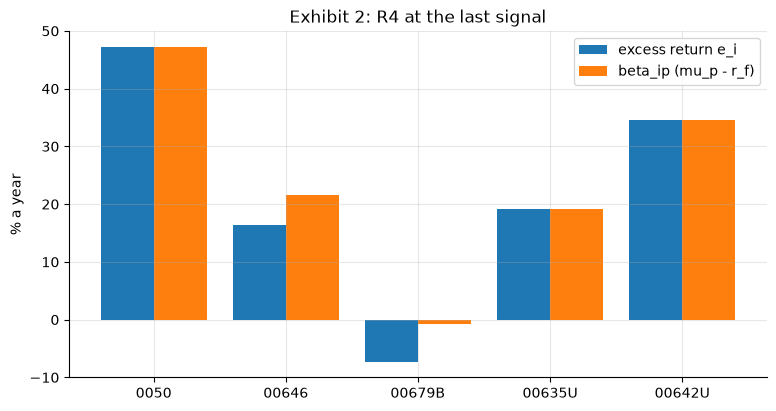

Sharpe ratio: 2.106733   [book: 2.106733]
bump 00646: Sharpe ratio: 2.107817   [book: 2.107817]
bump 00646: first-order gain: 0.001093   [book: 0.001093]
bump 00679B: Sharpe ratio: 2.108091   [book: 2.108091]
bump 00679B: first-order gain: 0.001365   [book: 0.001365]
r_f 0%: holds ['0050', '00635U', '00642U'], largest move 1.15 points
R4 Sharpe ratio at r_f 0%: 2.19   [book: 2.19]
r_f 2%: holds ['0050', '00635U', '00642U'], largest move 0.41 points
R4 Sharpe ratio at r_f 2%: 2.08   [book: 2.08]


In [5]:
volL = np.sqrt(np.diag(SL))
z = np.linalg.solve(SL, eL)
wt = z / z.sum()                                  # LM28's tangency (28.6)
w4L, w3L = maxsharpe(SL, eL), minvar(SL)
case = pl.DataFrame({"fund": FUNDS, "mean %": np.round(100 * muL, 2), "volatility %": np.round(100 * volL, 2),
                     "e %": np.round(100 * eL, 2), "tangency %": np.round(100 * wt, 2),
                     "R4 %": np.round(100 * np.where(w4L < ZERO, 0, w4L), 2)})
print(case)
show("tangency Sharpe ratio", sr(wt, SL, eL), ".2f", "2.18")
show("R4 Sharpe ratio", sr(w4L, SL, eL), ".2f", "2.11")
show("tangency gross (%)", 100 * np.abs(wt).sum(), ".0f", "252")
show("tangency volatility (%)", 100 * vol(wt, SL), ".2f", "31.94")
show("R4 volatility (%)", 100 * vol(w4L, SL), ".2f", "18.85")

# Example 5: the KKT quantities of (29.6)-(29.7)
y4 = w4L / (eL @ w4L)
lam = float(2 * y4 @ SL @ y4)
nu = 2 * SL @ y4 - lam * eL
beta = SL @ w4L / (w4L @ SL @ w4L)
ep = float(w4L @ eL)
show("lambda", lam, ".5f", "0.45062")
show("nu 00646", nu[1], ".5f", "0.02337")
show("nu 00679B", nu[2], ".5f", "0.02920")
print("betas", np.round(beta, 3), "  [book: 1.190, 0.544, -0.020, 0.483, 0.871]")
show("mu_p - r_f (%)", 100 * ep, ".2f", "39.72")
show("00646: nu / lambda (points)", 100 * nu[1] / lam, ".2f", "5.19")
show("00679B: nu / lambda (points)", 100 * nu[2] / lam, ".2f", "6.48")
assert np.abs(nu / lam - (beta * ep - eL)).max() < 1e-12      # (29.7)

fig, ax = plt.subplots()
pos = np.arange(N)
ax.bar(pos - 0.2, 100 * eL, 0.4, label="excess return e_i")
ax.bar(pos + 0.2, 100 * beta * ep, 0.4, label="beta_ip (mu_p - r_f)")
ax.set_xticks(pos, FUNDS)
ax.set_ylabel("% a year")
ax.set_title("Exhibit 2: R4 at the last signal")
ax.legend()
plt.show()

# Example 6: relax one bound y_i >= 0 to y_i >= -0.01
srL = sr(w4L, SL, eL)
show("Sharpe ratio", srL, ".6f", "2.106733")
for name, printed, pred in (("00646", "2.107817", "0.001093"), ("00679B", "2.108091", "0.001365")):
    i = FUNDS.index(name)
    lb = np.zeros(N)
    lb[i] = -0.01
    wb = homog(SL, eL, lb=lb)
    assert np.abs(wb - homog(SL, eL, "OSQP", lb=lb)).max() < 1e-6
    show(f"bump {name}: Sharpe ratio", sr(wb, SL, eL), ".6f", printed)
    show(f"bump {name}: first-order gain", srL**3 * nu[i] * 0.01 / 2, ".6f", pred)

# r_f at 0% and 2% (the shared decision "Risk-free rate")
for rf, printed in ((0.0, "2.19"), (0.02, "2.08")):
    wr = maxsharpe(SL, muL - rf)
    print(f"r_f {rf:.0%}: holds {[s for s, v in zip(FUNDS, wr) if v > ZERO]}, largest move "
          f"{100 * np.abs(wr - w4L).max():.2f} points")
    show(f"R4 Sharpe ratio at r_f {rf:.0%}", sr(wr, SL, muL - rf), ".2f", printed)

## Part 5 — U28's long-only minimum variance, Example 4

The sector closes are repaired as in Lab 23: every close listed in `sectors_close_repairs.csv` is replaced by its 13:30:00 value. On FinMind's free plan the 13:30:00 values are not available (`TaiwanStockEvery5SecondsIndex` is a paid dataset), so `close_1330` is empty and the cell **drops** those closes instead; the returns into and out of each dropped date leave the sample, and the U28 numbers then differ from the book's. Nothing is ever estimated.

In [6]:
AGGREGATES = ("Electronic", "ChemicalBiotechnologyMedicalCare")
raw = pl.read_csv(DATA / "sectors_close_raw.csv", infer_schema_length=None).sort("date")
rep = pl.read_csv(DATA / "sectors_close_repairs.csv", infer_schema_length=None,
                  schema_overrides={"close_1330": pl.Float64})
fixed = raw
for sid in rep["id"].unique(maintain_order=True).to_list():
    g = rep.filter(pl.col("id") == pl.lit(sid)).select("date", pl.col("close_1330").alias("_new"),
                                                        pl.lit(True).alias("_listed"))
    fixed = (fixed.join(g, on="date", how="left").sort("date")
                  .with_columns(pl.when(pl.col("_listed")).then(pl.col("_new")).otherwise(pl.col(sid)).alias(sid))
                  .drop("_new", "_listed"))
FULL_DATA = int(rep["close_1330"].is_not_null().sum()) == rep.height
U28 = [c for c in raw.columns if c not in ("date", "TAIEX", *AGGREGATES)]
cl = fixed.filter(pl.col("date").is_between(pl.lit("2008-12-01"), pl.lit("2026-10-08"))).sort("date")
P = cl.select(U28).to_numpy()
ok = ~np.isnan(P).any(axis=1)
P, cd = P[ok], np.array(cl["date"].to_list())[ok]
XU = P[1:] / P[:-1] - 1
AU = XU.shape[0] / ((date.fromisoformat(cd[-1]) - date.fromisoformat(cd[0])).days / 365.25)
SU = AU * cov0(XU)
print(f"full data: {FULL_DATA}; {len(U28)} sectors, T = {XU.shape[0]}, A = {AU:.2f}   [book: T = 4,382, A = 245.48]")
wU = minvar(SU)
heldU = [U28[i] for i in range(len(U28)) if wU[i] > ZERO]
bU = SU @ wU / (wU @ SU @ wU)
outU = [i for i in range(len(U28)) if wU[i] <= ZERO]
lo, hi = min(outU, key=lambda i: bU[i]), max(outU, key=lambda i: bU[i])
zU = np.linalg.solve(SU, np.ones(len(U28)))
wuU = zU / zU.sum()
w1 = minvar(AU * cov0(XU[:XU.shape[0] // 2]))
held1 = [U28[i] for i in range(len(U28)) if w1[i] > ZERO]
print(f"held {len(heldU)} of {len(U28)}: {heldU}")
print(f"volatility {100 * vol(wU, SU):.2f}%  lambda {2 * wU @ SU @ wU:.4f}   [book: 12.10%, 0.0293]")
print(f"excluded betas from {bU[lo]:.6f} ({U28[lo]}) to {bU[hi]:.3f} ({U28[hi]}), all >= 1: {min(bU[outU]) >= 1 - 1e-12}")
print(f"unconstrained w_mv: {int((wuU < -ZERO).sum())} shorts, gross {np.abs(wuU).sum():.2f}   [book: 12, 2.24]")
print(f"first half: {len(held1)} held, {len(set(held1) & set(heldU))} of them the full sample's   [book: 9, 7]")
print(f"candidate active sets 2^28 = {2**28:,}")
if FULL_DATA:
    show("U28 volatility (%)", 100 * vol(wU, SU), ".2f", "12.10")
    show("Cement's beta", bU[U28.index("Cement")], ".6f", "1.000019")

full data: True; 28 sectors, T = 4382, A = 245.48   [book: T = 4,382, A = 245.48]
held 9 of 28: ['BiotechnologyMedicalCare', 'CommunicationsInternet', 'Food', 'InformationService', 'IronSteel', 'OilGasElectricity', 'Rubber', 'Tourism', 'TradingConsumersGoods']
volatility 12.10%  lambda 0.0293   [book: 12.10%, 0.0293]
excluded betas from 1.000019 (Cement) to 1.480 (Optoelectronic), all >= 1: True
unconstrained w_mv: 12 shorts, gross 2.24   [book: 12, 2.24]
first half: 9 held, 7 of them the full sample's   [book: 9, 7]
candidate active sets 2^28 = 268,435,456
U28 volatility (%): 12.10   [book: 12.10]
Cement's beta: 1.000019   [book: 1.000019]


## Part 6 — The cap, the limits and the frontiers: Example 7, Exhibit 3, Exhibit 4, Example 2, Example 3

capped weights (%) [ 6.  26.9 40.  19.3  7.8]   [book: 6.0, 26.9, 40.0, 19.3, 7.8]
capped volatility (%): 10.52   [book: 10.52]
V: 0.0110665   [book: 0.0110665]
nu_cap: 0.010543   [book: 0.010543]
lambda = 2V + 0.40 nu_cap: 0.026350   [book: 0.026350]
free funds' beta: 1.191   [book: 1.191]
00679B's beta: 0.714   [book: 0.714]
variance change at a 41% cap: -0.000102   [book: -0.000102]
first-order prediction: -0.000105   [book: -0.000105]
signals where R3's largest weight exceeds 40%: 63   [book: 63]
unconstrained        weights [114.24 -27.75 -48.48  31.07  30.92]  SR 2.18  volatility 31.94%
gross <= 150%        weights [ 78.82  -7.59 -17.41  23.36  22.82]  SR 2.16  volatility 23.01%
long-only (R4)       weights [62.77  0.    0.   18.37 18.86]  SR 2.11  volatility 18.85%
long-only, cap 40%   weights [40.   14.37  0.   27.48 18.15]  SR 2.00  volatility 16.40%


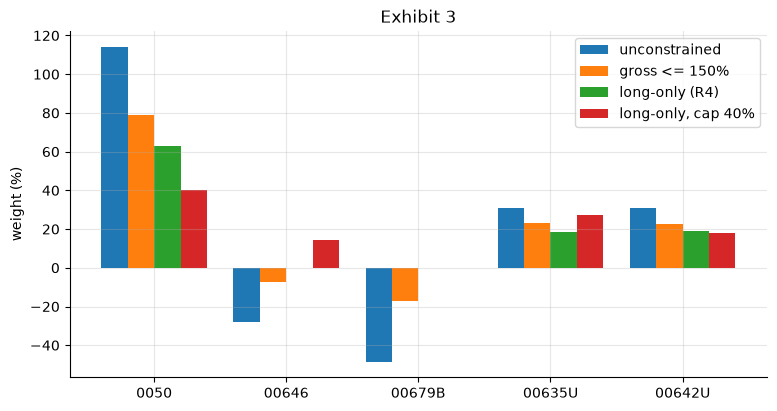

coincidence from (%): 4.12   [book: 4.12]
coincidence to (%): 30.44   [book: 30.44]
40% target, unconstrained (%): 18.29   [book: 18.29]
40% target, long-only (%): 18.32   [book: 18.32]


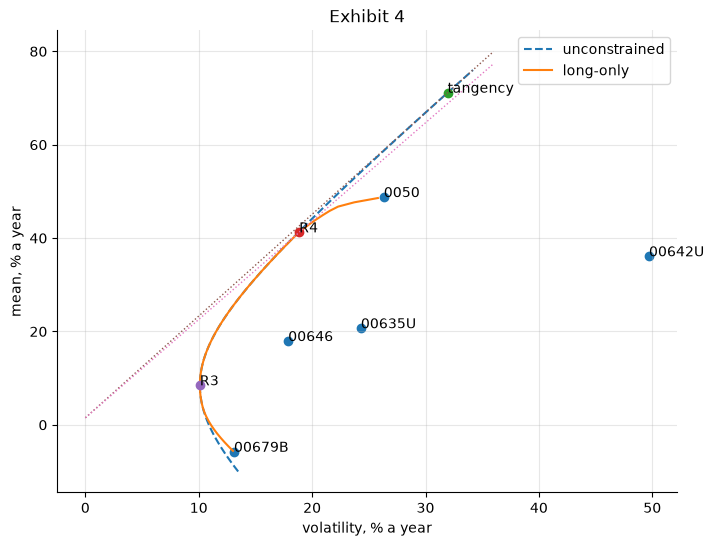

LP weights (%) [40.  0.  0. 20. 40.]
LP mean (%): 38.08   [book: 38.08]
cvxpy's default solver for the LP: CLARABEL
15% caps: infeasible inf None
budget only: unbounded inf None
R3's variance on the last window: 0.0102   [book: 0.0102]


In [7]:
# Example 7: R3 with a 40% cap, by OSQP; the cap binds on 00679B
w = cp.Variable(N)
c_budget, c_cap = cp.sum(w) == 1, w <= 0.40
_, wc = cvx(cp.quad_form(w, cp.psd_wrap(SL)), [c_budget, w >= 0, c_cap], "OSQP", OSQP_BOOK)
V = float(wc @ SL @ wc)
g = 2 * SL @ wc
free = [i for i in range(N) if i != 2]
lam_c = float(g[free].mean())
nu_c = lam_c - float(g[2])
print("capped weights (%)", np.round(100 * wc, 1), "  [book: 6.0, 26.9, 40.0, 19.3, 7.8]")
show("capped volatility (%)", 100 * math.sqrt(V), ".2f", "10.52")
show("V", V, ".7f", "0.0110665")
show("nu_cap", nu_c, ".6f", "0.010543")
show("lambda = 2V + 0.40 nu_cap", 2 * V + 0.40 * nu_c, ".6f", "0.026350")
show("free funds' beta", lam_c / (2 * V), ".3f", "1.191")
show("00679B's beta", (lam_c - nu_c) / (2 * V), ".3f", "0.714")
w = cp.Variable(N)
_, w41 = cvx(cp.quad_form(w, cp.psd_wrap(SL)), [cp.sum(w) == 1, w >= 0, w <= 0.41], "OSQP", OSQP_BOOK)
show("variance change at a 41% cap", float(w41 @ SL @ w41) - V, ".6f", "-0.000102")
show("first-order prediction", -nu_c * 0.01, ".6f", "-0.000105")
show("signals where R3's largest weight exceeds 40%",
     sum(1 for k in range(len(sched)) if minvar(window(k)[1]).max() > 0.40 + 1e-12), "d", "63")

# Exhibit 3: the maximum-Sharpe portfolio under four sets of limits
lims = {"unconstrained": wt, "gross <= 150%": homog(SL, eL, gross=1.5), "long-only (R4)": w4L,
        "long-only, cap 40%": homog(SL, eL, cap=0.40)}
for name, wl_ in lims.items():
    print(f"{name:20s} weights {np.round(100 * np.where(np.abs(wl_) < ZERO, 0, wl_), 2)}  SR {sr(wl_, SL, eL):.2f}  "
          f"volatility {100 * vol(wl_, SL):.2f}%")
fig, ax = plt.subplots()
for k, (name, wl_) in enumerate(lims.items()):
    ax.bar(np.arange(N) + 0.2 * (k - 1.5), 100 * wl_, 0.2, label=name)
ax.set_xticks(np.arange(N), FUNDS)
ax.set_ylabel("weight (%)")
ax.set_title("Exhibit 3")
ax.legend()
plt.show()

# Exhibit 4: the unconstrained frontier (28.4) in closed form and the long-only frontier by CLARABEL
Kf = np.vstack([ONE, muL])
Bf = np.linalg.solve(SL, Kf.T)
Gf = Kf @ Bf


def w_front(m):
    return Bf @ np.linalg.solve(Gf, np.array([1.0, m]))


def lo_front(m):
    w = cp.Variable(N)
    _, v = cvx(cp.quad_form(w, cp.psd_wrap(SL)), [cp.sum(w) == 1, muL @ w == m, w >= 0], "CLARABEL", CLARABEL_BOOK)
    return v


a0, a1 = w_front(0.0), w_front(1.0) - w_front(0.0)
lo_m = max(-a0[i] / a1[i] for i in range(N) if a1[i] > 0)
hi_m = min(-a0[i] / a1[i] for i in range(N) if a1[i] < 0)
show("coincidence from (%)", 100 * lo_m, ".2f", "4.12")
show("coincidence to (%)", 100 * hi_m, ".2f", "30.44")
show("40% target, unconstrained (%)", 100 * vol(w_front(0.40), SL), ".2f", "18.29")
show("40% target, long-only (%)", 100 * vol(lo_front(0.40), SL), ".2f", "18.32")
ms = np.linspace(muL.min() + 0.002, muL.max() - 0.002, 60)
mu_grid = np.linspace(-0.10, 0.76, 87)
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot([100 * vol(w_front(m), SL) for m in mu_grid], 100 * mu_grid, "--", label="unconstrained")
ax.plot([100 * vol(lo_front(m), SL) for m in ms], 100 * ms, label="long-only")
for wl_, lab in ((wt, "tangency"), (w4L, "R4"), (w3L, "R3")):
    ax.plot(100 * vol(wl_, SL), 100 * wl_ @ muL, "o")
    ax.annotate(lab, (100 * vol(wl_, SL), 100 * wl_ @ muL))
for s_, slope in ((0, sr(wt, SL, eL)), (1, sr(w4L, SL, eL))):
    ax.plot([0, 36], [1.5, 1.5 + slope * 36], ":", lw=1)
ax.scatter(100 * volL, 100 * muL)
for i, s in enumerate(FUNDS):
    ax.annotate(s, (100 * volL[i], 100 * muL[i]))
ax.set_xlabel("volatility, % a year")
ax.set_ylabel("mean, % a year")
ax.set_title("Exhibit 4")
ax.legend()
plt.show()

# Example 2 and Example 3
w = cp.Variable(N)
plp, wlp = cvx(muL @ w, [cp.sum(w) == 1, w >= 0, w <= 0.40], "CLARABEL", None, sense="max")
print("LP weights (%)", np.round(100 * np.where(np.abs(wlp) < ZERO, 0, wlp), 4))
show("LP mean (%)", 100 * float(muL @ wlp), ".2f", "38.08")
w = cp.Variable(N)
pdef = cp.Problem(cp.Maximize(muL @ w), [cp.sum(w) == 1, w >= 0, w <= 0.40])
pdef.solve()
print("cvxpy's default solver for the LP:", pdef.solver_stats.solver_name)
w = cp.Variable(N)
pinf = cp.Problem(cp.Minimize(cp.quad_form(w, cp.psd_wrap(SL))), [cp.sum(w) == 1, w >= 0, w <= 0.15])
pinf.solve(solver=cp.CLARABEL)
print("15% caps:", pinf.status, pinf.value, w.value)
w = cp.Variable(N)
punb = cp.Problem(cp.Maximize(muL @ w), [cp.sum(w) == 1])
punb.solve(solver=cp.CLARABEL)
print("budget only:", punb.status, punb.value, w.value)
show("R3's variance on the last window", float(w3L @ SL @ w3L), ".4f", "0.0102")

## Part 7 — Costs in the objective: Example 8, Exhibit 5 and Exhibit 6

A target set at its trade's close drifts with each fund's wealth-frame returns until the next signal's close. The cost-penalized problem (29.9) goes to cvxpy as LM27's formula, `COMMISSION * norm1(w - w_drift) + tax @ pos(w_drift - w)`.

drifted weights (%) [ 2.2 31.8 35.7 23.9  6.4]   [book: 2.2, 31.8, 35.7, 23.9, 6.4]
turnover to the new R3 (%): 18.72   [book: 18.72]
its cost (% of wealth): 0.072   [book: 0.072]
theta = 1 trades (points) [ 0.  -9.9  4.6  6.7 -1.4]
turnover (%): 11.30   [book: 11.30]
cost (%): 0.0435   [book: 0.0435]
volatility (%): 9.03   [book: 9.03]
R3's volatility (%): 8.97   [book: 8.97]
no trade's volatility (%): 9.51   [book: 9.51]
lambda: 0.016660   [book: 0.016660]
gradients [0.017684 0.019085 0.015235 0.015235 0.019085]  band: buy 0.015235 sell 0.019085 00679B 0.018085


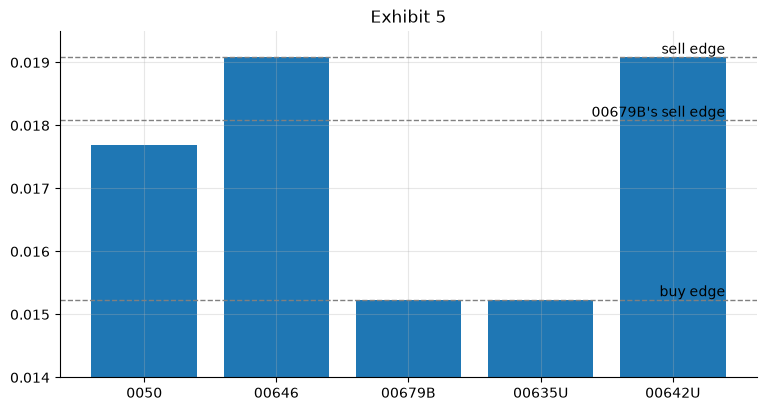

no-trade threshold: 3.20   [book: 3.20]
shape: (7, 6)
┌───────┬───────────────┬─────────────────────┬──────────────────┬────────────────────┬────────────┐
│ theta ┆ turnover % of ┆ cost % of theta 0   ┆ no trade (of 91) ┆ vol given up, mean ┆ largest bp │
│ ---   ┆ theta 0       ┆ ---                 ┆ ---              ┆ bp                 ┆ ---        │
│ f64   ┆ ---           ┆ f64                 ┆ i64              ┆ ---                ┆ f64        │
│       ┆ f64           ┆                     ┆                  ┆ f64                ┆            │
╞═══════╪═══════════════╪═════════════════════╪══════════════════╪════════════════════╪════════════╡
│ 0.0   ┆ 100.0         ┆ 100.0               ┆ 0                ┆ 0.0                ┆ 0.0        │
│ 0.25  ┆ 58.4          ┆ 59.0                ┆ 11               ┆ 0.4                ┆ 1.5        │
│ 0.5   ┆ 44.7          ┆ 45.5                ┆ 18               ┆ 1.5                ┆ 3.8        │
│ 1.0   ┆ 31.5          ┆ 31.8       

In [8]:
def drift(w, i0, i1):
    # weights set at the close of wealth date i0, grown through the close of wealth date i1
    h = w * np.prod(1 + W[i0 + 1:i1 + 1], axis=0)
    return h / h.sum()


def penalized(S, wd, theta, solver="OSQP"):
    w = cp.Variable(N)
    obj = cp.quad_form(w, cp.psd_wrap(S)) + theta * (COMMISSION * cp.norm1(w - wd) + TAX @ cp.pos(wd - w))
    _, v = cvx(obj, [cp.sum(w) == 1, w >= 0], solver, OSQP_BOOK if solver == "OSQP" else CLARABEL_BOOK)
    return v


kc = [s for s, _ in sched].index("2025-04-30")
Sp, Sc = window(kc - 1)[1], window(kc)[1]
wdc = drift(minvar(Sp), WD.index(sched[kc - 1][1]), WD.index(sched[kc][0]))
w3c = minvar(Sc)
print("drifted weights (%)", np.round(100 * wdc, 1), "  [book: 2.2, 31.8, 35.7, 23.9, 6.4]")
show("turnover to the new R3 (%)", 100 * 0.5 * np.abs(w3c - wdc).sum(), ".2f", "18.72")
show("its cost (% of wealth)", 100 * cost(w3c - wdc), ".3f", "0.072")
wp1 = penalized(Sc, wdc, 1.0)
d1 = wp1 - wdc
print("theta = 1 trades (points)", np.round(100 * np.where(np.abs(d1) < ZERO, 0, d1), 1))
show("turnover (%)", 100 * 0.5 * np.abs(d1).sum(), ".2f", "11.30")
show("cost (%)", 100 * cost(d1), ".4f", "0.0435")
show("volatility (%)", 100 * vol(wp1, Sc), ".2f", "9.03")
show("R3's volatility (%)", 100 * vol(w3c, Sc), ".2f", "8.97")
show("no trade's volatility (%)", 100 * vol(wdc, Sc), ".2f", "9.51")
gp = 2 * Sc @ wp1
buy = d1 > ZERO
lam1 = float((gp[buy] + COMMISSION).mean())
show("lambda", lam1, ".6f", "0.016660")
print("gradients", np.round(gp, 6), " band: buy", round(lam1 - COMMISSION, 6), "sell", round(lam1 + COMMISSION + 0.001, 6),
      "00679B", round(lam1 + COMMISSION, 6))
fig, ax = plt.subplots()
ax.bar(FUNDS, gp)
for yv, lab in ((lam1 - COMMISSION, "buy edge"), (lam1 + COMMISSION, "00679B's sell edge"),
                (lam1 + COMMISSION + 0.001, "sell edge")):
    ax.axhline(yv, ls="--", lw=1, color="grey")
    ax.annotate(lab, (4.4, yv), ha="right", va="bottom")
ax.set_ylim(0.014, 0.0195)
ax.set_title("Exhibit 5")
plt.show()
Gd = 2 * Sc @ wdc
bar = max((Gd[i] - Gd[j]) / (2 * COMMISSION + TAX[i]) for i in range(N) for j in range(N) if i != j)
show("no-trade threshold", bar, ".2f", "3.20")

# Exhibit 6: R3's path with the cost penalty, planned at each signal close
rows = []
for th in (0.0, 0.25, 0.5, 1.0, 2.0, 5.0, 10.0):
    prev, iprev, to, cs, gap, quiet = None, -1, 0.0, 0.0, [], 0
    for k, (sg, tr) in enumerate(sched):
        S = window(k)[1]
        w3 = minvar(S)
        if prev is None:
            fk = w3
        else:
            wd = drift(prev, iprev, WD.index(sg))
            fk = penalized(S, wd, th) if th > 0 else w3
            fk = np.clip(fk, 0, None)
            fk = fk / fk.sum()
            d = fk - wd
            to += 0.5 * float(np.abs(d).sum())
            cs += cost(d)
            gap.append(vol(fk, S) - vol(w3, S))
            quiet += int(0.5 * float(np.abs(d).sum()) < ZERO)
        prev, iprev = fk, WD.index(tr)
    rows.append((th, to, cs, quiet, 1e4 * float(np.mean(gap)), 1e4 * float(np.max(gap))))
to0, cs0 = rows[0][1], rows[0][2]
sweep = pl.DataFrame([{"theta": th, "turnover % of theta 0": round(100 * to / to0, 1),
                       "cost % of theta 0": round(100 * cs / cs0, 1), "no trade (of 91)": q,
                       "vol given up, mean bp": round(vm, 1) + 0.0, "largest bp": round(vx, 1) + 0.0}
                      for th, to, cs, q, vm, vx in rows])
print(sweep)
show("theta 1: planned turnover (% of theta 0)", 100 * rows[3][1] / to0, ".1f", "31.5")

## Part 8 — Solvers and checks: Example 9 and Exhibit 7

R3 and R4 are solved in daily units ($\hat\Sigma$) and in annual units ($A\hat\Sigma$) by OSQP and CLARABEL, at cvxpy's defaults and at the book's tolerances, at all 92 signals; each cell is the largest weight gap to the exact solution. Exhibit 7 prints R3's cells; here are all 16.

In [9]:
def gap_run(k, rule, unit, solver, opts):
    x = window(k)[0]
    S_ann, e_ann = A * cov0(x), A * x.mean(axis=0) - RF
    ex = minvar(S_ann) if rule == "R3" else maxsharpe(S_ann, e_ann)
    s = 1.0 if unit == "daily" else A
    a = ONE if rule == "R3" else (s / A) * e_ann
    y = cp.Variable(N)
    _, v = cvx(cp.quad_form(y, cp.psd_wrap(s * cov0(x))), [a @ y == 1, y >= 0], solver, opts)
    return math.inf if v is None else float(np.abs(v / v.sum() - ex).max())


cases = [("OSQP", None, "default"), ("CLARABEL", None, "default"), ("OSQP", OSQP_BOOK, "book"),
         ("CLARABEL", CLARABEL_BOOK, "book")]
t0 = time.perf_counter()
audit = []
for rule in ("R3", "R4"):
    for unit in ("daily", "annual"):
        for sv, op, lab in cases:
            first = gap_run(0, rule, unit, sv, op)
            worst = max(gap_run(k, rule, unit, sv, op) for k in range(len(sched)))
            audit.append({"rule": rule, "units": unit, "solver": sv, "tolerances": lab,
                          "first signal": f"{first:.1e}", "worst of 92": f"{worst:.1e}"})
print(pl.DataFrame(audit))
book = {("R3", "daily", "OSQP", "default"): ("8.3e-09", "1.1e-08"), ("R3", "daily", "CLARABEL", "default"): ("8.6e-04", "2.1e-03"),
        ("R3", "daily", "CLARABEL", "book"): ("3.2e-08", "3.2e-07"), ("R3", "annual", "CLARABEL", "default"): ("1.6e-05", "3.4e-05"),
        ("R3", "annual", "CLARABEL", "book"): ("2.0e-11", "8.9e-09"), ("R4", "annual", "CLARABEL", "default"): (None, "9.5e-07")}
for r in audit:
    key = (r["rule"], r["units"], r["solver"], r["tolerances"])
    if key in book:
        if book[key][0] is not None:
            show(f"{key} first signal", float(r["first signal"]), ".1e", book[key][0])
        show(f"{key} worst of 92", float(r["worst of 92"]), ".1e", book[key][1])
    if r["solver"] == "OSQP" and r["units"] == "annual" and r["rule"] == "R3":
        assert float(r["worst of 92"]) < 1e-15                      # printed as "below 1e-15"
print(f"{time.perf_counter() - t0:.1f} s")
w30d = minvar(cov0(x0))
print(f"R3's optimal variance at the first signal: daily {w30d @ cov0(x0) @ w30d:.3e}, "
      f"annual {w30d @ (A * cov0(x0)) @ w30d:.3e}   [book: 1.035e-5, 2.515e-3]")

# Example 9: R4 at the last signal by each solver, KKT residuals with lambda = 2 y'Sigma y
for sv, op in (("OSQP", OSQP_BOOK), ("CLARABEL", CLARABEL_BOOK)):
    y = cp.Variable(N)
    pr, v = cvx(cp.quad_form(y, cp.psd_wrap(SL)), [eL @ y == 1, y >= 0], sv, op)
    lam_h = float(2 * v @ SL @ v)
    nu_h = 2 * SL @ v - lam_h * eL
    on = v > ZERO
    print(f"{sv}: status {pr.status}; stationarity {np.abs(nu_h[on]).max():.1e}, smallest nu {nu_h.min():.1e}, "
          f"complementarity {np.abs(nu_h * v).max():.1e}, min y {v.min():.1e}, weight gap "
          f"{np.abs(v / v.sum() - w4L).max():.1e}")
act = [i for i in range(N) if w4L[i] > ZERO]
zS = np.linalg.solve(SL[np.ix_(act, act)], eL[act])
print("closed form (28.6) on the held funds against nnls:", f"{np.abs(zS / zS.sum() - w4L[act]).max():.1e}")
w = cp.Variable(N)
c0 = cp.sum(w) == 1
cvx(cp.quad_form(w, cp.psd_wrap(SL)), [c0, w >= 0], "OSQP", OSQP_BOOK)
show("R3's budget dual (cvxpy reports -lambda)", float(c0.dual_value), ".6f", "-0.020396")
y = cp.Variable(N)
c0, c1 = eL @ y == 1, y >= 0
cvx(cp.quad_form(y, cp.psd_wrap(SL)), [c0, c1], "CLARABEL", CLARABEL_BOOK)
show("R4's dual of e'y = 1", float(c0.dual_value), ".4f", "-0.4506")
print("bound duals", np.round(np.asarray(c1.dual_value), 4), "  [book: 0.0234 (00646), 0.0292 (00679B)]")

shape: (16, 6)
┌──────┬────────┬──────────┬────────────┬──────────────┬─────────────┐
│ rule ┆ units  ┆ solver   ┆ tolerances ┆ first signal ┆ worst of 92 │
│ ---  ┆ ---    ┆ ---      ┆ ---        ┆ ---          ┆ ---         │
│ str  ┆ str    ┆ str      ┆ str        ┆ str          ┆ str         │
╞══════╪════════╪══════════╪════════════╪══════════════╪═════════════╡
│ R3   ┆ daily  ┆ OSQP     ┆ default    ┆ 8.3e-09      ┆ 1.1e-08     │
│ R3   ┆ daily  ┆ CLARABEL ┆ default    ┆ 8.6e-04      ┆ 2.1e-03     │
│ R3   ┆ daily  ┆ OSQP     ┆ book       ┆ 8.3e-09      ┆ 1.1e-08     │
│ R3   ┆ daily  ┆ CLARABEL ┆ book       ┆ 3.2e-08      ┆ 3.2e-07     │
│ R3   ┆ annual ┆ OSQP     ┆ default    ┆ 1.1e-16      ┆ 3.9e-16     │
│ R3   ┆ annual ┆ CLARABEL ┆ default    ┆ 1.6e-05      ┆ 3.4e-05     │
│ R3   ┆ annual ┆ OSQP     ┆ book       ┆ 1.1e-16      ┆ 3.9e-16     │
│ R3   ┆ annual ┆ CLARABEL ┆ book       ┆ 2.0e-11      ┆ 8.9e-09     │
│ R4   ┆ daily  ┆ OSQP     ┆ default    ┆ 7.5e-09      ┆ 1.0e-

## Part 9 — Practice problems 9, 10, 11 and 12

Problem 12 is Part 8: the daily objective is $A$ times smaller than the annual one, CLARABEL's default gap tolerance $10^{-8}$ is absolute, and OSQP's polishing re-solves on the constraints it finds active.

In [10]:
# Problem 9: the first window
w30, w31 = minvar(S0), maxsharpe(S0, e0)
print("R3 (%)", np.round(100 * w30, 1), "  [book: 10.7, 22.5, 41.4, 25.0, 0.4]")
z = np.linalg.solve(S0, ONE)
print("largest gap between R3 and (28.2)'s w_mv:", f"{np.abs(w30 - z / z.sum()).max():.1e}")
print("R4 (%)", np.round(100 * w31, 2), "  [book: 10.57, 52.44, 36.99, 0, 0]")
show("R4's in-sample Sharpe ratio", sr(w31, S0, e0), ".3f", "0.802")
y31 = w31 / (w31 @ e0)
lam31 = float(2 * y31 @ S0 @ y31)
nu31 = 2 * S0 @ y31 - lam31 * e0
show("00635U: nu / lambda (points)", 100 * nu31[3] / lam31, ".2f", "0.25")
show("00642U: nu / lambda (points)", 100 * nu31[4] / lam31, ".2f", "8.01")
act0 = [i for i in range(N) if w31[i] > ZERO]
z0 = np.linalg.solve(S0[np.ix_(act0, act0)], e0[act0])
print("(28.6) on the held funds against nnls:", f"{np.abs(z0 / z0.sum() - w31[act0]).max():.1e}")

# Problem 10: a 5% turnover limit, and the penalty theta TO at theta = its multiplier
w = cp.Variable(N)
c_to = 0.5 * cp.norm1(w - wdc) <= 0.05
_, wto = cvx(cp.quad_form(w, cp.psd_wrap(Sc)), [cp.sum(w) == 1, w >= 0, c_to], "CLARABEL", CLARABEL_BOOK)
mult = float(c_to.dual_value)
print("weights (%)", np.round(100 * wto, 1), "  [book: 2.2, 27.4, 36.9, 27.7, 5.8]")
show("volatility (%)", 100 * vol(wto, Sc), ".2f", "9.24")
show("multiplier of the limit", mult, ".5f", "0.00825")
w = cp.Variable(N)
_, wpen = cvx(cp.quad_form(w, cp.psd_wrap(Sc)) + mult * 0.5 * cp.norm1(w - wdc), [cp.sum(w) == 1, w >= 0],
              "CLARABEL", CLARABEL_BOOK)
print("penalty against limit, largest gap:", f"{np.abs(wpen - wto).max():.1e}", " (below 1e-9)")

# Problem 11: financed leverage up to 25% volatility
f = cp.Variable(N)
for spread, L_book, ex_book in ((0.0, "132.6", "52.67"), (SPREAD, "131.0", "52.65")):
    wb = maxsharpe(SL, eL - spread)               # the long-only tangency at r_f + spread
    fx = 0.25 / vol(wb, SL) * wb
    assert fx.sum() > 1 and np.abs(fx).sum() <= 1.5
    obj = eL @ f - spread * cp.pos(cp.sum(f) - 1)
    cons = [cp.quad_form(f, cp.psd_wrap(SL)) <= 0.25**2, f >= 0, cp.norm1(f) <= 1.5]
    _, fc = cvx(obj, cons, "CLARABEL", CONE_BOOK, sense="max")
    _, fs = cvx(obj, cons, "SCS", {"eps": 1e-9, "max_iters": 200000}, sense="max")
    print(f"spread {spread:.0%}: f (%) {np.round(100 * fx, 2)}; CLARABEL {np.abs(fc - fx).max():.1e}, "
          f"SCS {np.abs(fs - fx).max():.1e}")
    show("  net exposure L (%)", 100 * fx.sum(), ".1f", L_book)
    show("  excess return before financing (%)", 100 * eL @ fx, ".2f", ex_book)
    if spread:
        show("  after financing (%)", 100 * (eL @ fx - spread * (fx.sum() - 1)), ".2f", "52.03")
for rf, L_book, ex_book in ((0.0, "132.2", "54.01"), (0.02, "130.6", "51.38")):
    e_ = muL - rf
    fx = 0.25 / vol(maxsharpe(SL, e_ - SPREAD), SL) * maxsharpe(SL, e_ - SPREAD)
    show(f"r_f {rf:.0%}, 2 points: L (%)", 100 * fx.sum(), ".1f", L_book)
    show(f"r_f {rf:.0%}, 2 points: after financing (%)", 100 * (e_ @ fx - SPREAD * (fx.sum() - 1)), ".2f", ex_book)

R3 (%) [10.7 22.5 41.4 25.   0.4]   [book: 10.7, 22.5, 41.4, 25.0, 0.4]
largest gap between R3 and (28.2)'s w_mv: 5.6e-17
R4 (%) [10.57 52.44 36.99  0.    0.  ]   [book: 10.57, 52.44, 36.99, 0, 0]
R4's in-sample Sharpe ratio: 0.802   [book: 0.802]
00635U: nu / lambda (points): 0.25   [book: 0.25]
00642U: nu / lambda (points): 8.01   [book: 8.01]
(28.6) on the held funds against nnls: 2.2e-16
weights (%) [ 2.2 27.4 36.9 27.7  5.8]   [book: 2.2, 27.4, 36.9, 27.7, 5.8]
volatility (%): 9.24   [book: 9.24]
multiplier of the limit: 0.00825   [book: 0.00825]
penalty against limit, largest gap: 1.6e-10  (below 1e-9)
spread 0%: f (%) [83.23  0.    0.   24.36 25.  ]; CLARABEL 6.8e-07, SCS 3.7e-15
  net exposure L (%): 132.6   [book: 132.6]
  excess return before financing (%): 52.67   [book: 52.67]
spread 2%: f (%) [84.36  0.    0.   21.83 24.81]; CLARABEL 3.9e-08, SCS 3.7e-15
  net exposure L (%): 131.0   [book: 131.0]
  excess return before financing (%): 52.65   [book: 52.65]
  after financin

## Part 10 — Extension: R4's active sets by enumeration (*In-sample*)

At the first signal, R4 has $2^5-1=31$ non-empty supports. For each, solve LM28's (28.6) on the support's funds, keep the candidates whose weights are non-negative and that pass the sign test of (29.7) for the funds outside, and confirm that exactly one survives and equals `nnls`'s answer. Then time the loop and extrapolate to U28's $2^{28}$ sets.

In [11]:
t0 = time.perf_counter()
survivors = []
for r in range(1, N + 1):
    for sup in itertools.combinations(range(N), r):
        sup = list(sup)
        zz = np.linalg.solve(S0[np.ix_(sup, sup)], e0[sup])
        if zz.sum() <= 0:
            continue
        w_ = np.zeros(N)
        w_[sup] = zz / zz.sum()
        if w_.min() < -1e-12:
            continue
        b_ = S0 @ w_ / (w_ @ S0 @ w_)
        gap_ = b_ * (w_ @ e0) - e0                    # (29.7): >= 0 for every fund outside the support
        if all(gap_[i] >= -1e-12 for i in range(N) if i not in sup):
            survivors.append((sup, w_))
dt = time.perf_counter() - t0
print(f"{len(survivors)} survivor(s): {[[FUNDS[i] for i in s] for s, _ in survivors]}; "
      f"gap to nnls {np.abs(survivors[0][1] - w31).max():.1e}")
print(f"31 supports in {dt * 1e3:.1f} ms; 2^28 supports of 28 assets would take about "
      f"{dt / 31 * 2**28 / 3600:.0f} hours at this rate (larger systems are slower)")
# your code: repeat at every signal and count how often the surviving support changes from one month to the next.
# The surviving active set is itself an estimate: LM30 studies how it moves with the window.

1 survivor(s): [['0050', '00646', '00679B']]; gap to nnls 2.2e-16
31 supports in 0.6 ms; 2^28 supports of 28 assets would take about 1 hours at this rate (larger systems are slower)
